# QPDK qubit test chip — 4 double-pad transmons on a U-shaped probeline (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/qubit_test_chip.pic.yml` (the `.py`
only loads it), <https://github.com/gdsfactory/quantum-rf-pdk> — **MIT licence** ("Copyright (c) 2024
gdsfactory", `LICENSE` of a depth-1 clone read 2026-11-03 into `build/external/quantum-rf-pdk`, never executed).
Spec: `docs/designs/qpdk/qubit_test_chip.md`. Four floating double-pad transmons (QPDK
`double_pad_transmon_with_bbox`), each with a readout line coupled to one probeline that runs east, turns, and
runs back west; series interdigital capacitors at the probeline input and output; two flux lines (top and bottom)
ending between the qubit pairs; four launchers.

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 4.25 × 6.2 mm chip area, launchers on its edge | the 7.5 × 7.5 mm Quantcore die (`QP.die_box(4250, 6200)`, centred on the source's chip area), Quantcore die frame (dicing L's, 3 × 3 alignment grids, boundary, device ID "QPDK-QTC") |
| pads | QPDK `launcher` on the 4.25 mm chip's edge | the same `BondPad`s, moved to **100 µm** (`frame.pad_edge`) from the die edge by the PDK pad rule (`edge="auto"`); the lead lines get longer |
| placement | — | the whole layout centred in the die, pads included (`QP.center_content`): the circuit shifted **+1660 µm** in x from the source frame, its east side 100 µm from the east die edge; the pads keep their 100 µm, the probeline leads get 2 mm longer (3638 µm) |
| substrate | Al on Si (εr 11.45) | sapphire 650 µm, εr 10.25 (frequencies are not the QPDK ones) |
| junctions | QPDK `squid_junction` (evaporated Al; no L_J stated) | Quantcore Nb/AlOx/Nb trilayer SQUIDs, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH (`QP.JJ_PARAMS`) |
| cheese | none (this is the unfilled sample; the filled one is `filled_qubit_test_chip`) | none of the source's, so the **PDK band** (chip `cheese: "auto"`): 5 µm holes, 20 µm gaps, 3 rows around the 3/0 keep-outs, at least 4 µm clear of 3/0 |
| components, lengths | — | kept: pad / pocket geometry, coupler plate, readout lengths 5000 / 4600 / 3600 / 4800 µm, coupled sections 800 / 400 / 400 / 800 µm, 16 µm resonator–probeline gap, IDCs, CPW 10/6 µm |

**Electrical model kept from the source:** QPDK's readout line runs from the coupler plate, through the coupled
section, to an etched **open** end: a λ/2 line. The rebuild uses an **open hanger** (`end="open"`) of the same
total length.

**Simplified (layout only):** our router puts the hanger at the *end* of a route, so each meander sits between
the qubit and the coupled section (QPDK meanders beyond the coupler), with r = 50 µm (QPDK 100 µm); the flux lines
end in a plain open CPW end (QPDK: a `tee` with two 10 µm open stubs); the launcher ports sit 110 µm further in
than QPDK's (BondPad's gap also runs behind the pad).

Steps: setup → PDK → die → pads → components → routes → DRC → netlist → LOM → FEM jobs → results back → one
change → fab export → snapshots → summary.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in step 13 (`qcc mask` does the
full file). `_qpdk` holds the QPDK cell defaults shared by the QPDK notebooks (launcher, double-pad transmon,
IDC, the trilayer SQUID, the die box and the centring check).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults, trilayer SQUID, die box, centring
from quantcore_circuits.designer import Designer
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/qubit_test_chip")           # step-by-step snapshots (build/ is not kept in the repo)
DX, DY = 100, 3100                               # Designer = QPDK source + (DX, DY), before centring

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction.** QPDK states no junction values, and its evaporated Al junctions are another process, so every
SQUID is the Quantcore trilayer SQUID on the PDK rule: two junctions of 0.25 × 0.6 µm (KQC's `junction_width` is
the straight finger; the bent finger stays at the PDK 0.6 µm) → R_n 45 kΩ in parallel, L_J 6.73 nH at zero flux,
C_J 15 fF. `QP.JJ_PARAMS` go on the `DoublePads` cell, `QP.JUNCTION` (L_J, C_J) is what the LOM and the FEM
junction ports use.

In [3]:
print("cell parameters:", QP.JJ_PARAMS)
print("LOM junction:   ", QP.JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


## 3 · The die and its frame

`QP.die_box(4250, 6200)` is the 7.5 mm Quantcore die centred on the source's 4250 × 6200 µm chip area, so the
Designer coordinates are the source's + (100, 3100) µm until the centring step. The chip name is the device ID
the frame writes on a free edge. No `with_grid`: the source has no cheese, so the build draws the PDK band (chip
`cheese` = `"auto"`).

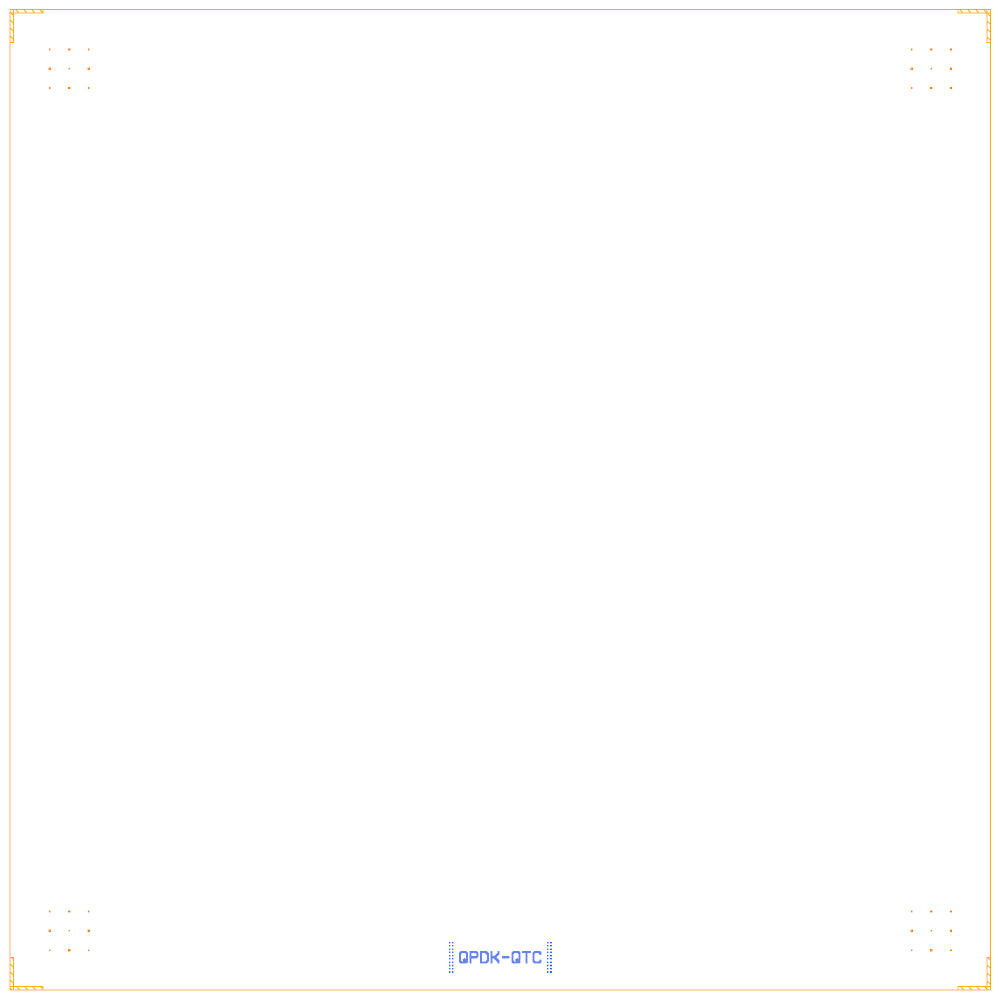

In [4]:
d = Designer("qubit_test_chip", box=QP.die_box(4250, 6200), chip={"name_chip": "QPDK-QTC"}, live=LIVE)
snap(d, STEPS / "1_die.png", size=(1000, 1000), width=400);

## 4 · Pads and the pad rule

QPDK's `launcher` (a 200 × 200 µm wire-bond pad on a 200/110 µm CPW, a 100 µm taper to the 10/6 µm line) is a
KQC-style `BondPad` here (`QP.LAUNCHER`). **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge`
(100 µm) from the die edge. `edge="auto"` in `d.add` applies it: the pad keeps its position along the
nearest die edge (the source's launcher axis) and slides perpendicular to it until its etch ends 100 µm from
the edge. The lead routes to the circuit simply get longer; nothing else moves. The table shows each pad's
distance after the rule (✓ = 100 µm).
Launchers: probeline in / out on the west edge (source `launcher_*` at (0, ±400)), flux top / bottom (source
(3000, ±3000)).

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PAD_IN | `BondPad` | w | 100.0 | ✓ |
| PAD_OUT | `BondPad` | w | 100.0 | ✓ |
| PAD_FT | `BondPad` | n | 100.0 | ✓ |
| PAD_FB | `BondPad` | s | 100.0 | ✓ |

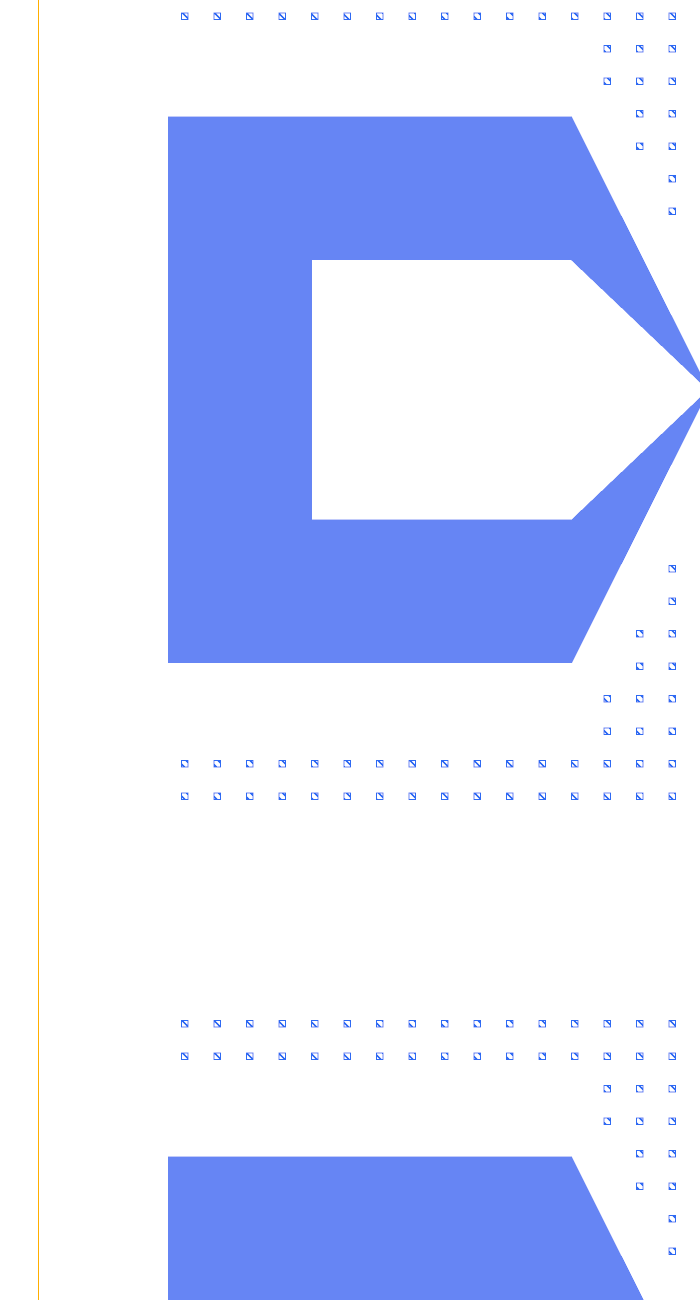

In [5]:
with d.batch():
    pin = d.add("PAD_IN", "BondPad", at=(DX + QP.LAUNCHER_DEPTH, DY + 400), rot=270, edge="auto", **QP.LAUNCHER)
    pout = d.add("PAD_OUT", "BondPad", at=(DX + QP.LAUNCHER_DEPTH, DY - 400), rot=270, edge="auto", **QP.LAUNCHER)
    pft = d.add("PAD_FT", "BondPad", at=(DX + 3000, 6200 - QP.LAUNCHER_DEPTH), rot=180, edge="auto", **QP.LAUNCHER)
    pfb = d.add("PAD_FB", "BondPad", at=(DX + 3000, QP.LAUNCHER_DEPTH), rot=0, edge="auto", **QP.LAUNCHER)
rebuild(d)
display(Markdown(pads_md(d)))
x0, y0, _, _ = d.design.chip.box
_, py = port_xy(d, "PAD_IN.a")
snap(d, STEPS / "2_pads.png", box=(x0 - 20, py - 700, x0 + 500, py + 300), size=(700, 1300), width=300);

## 5 · Components

**Series IDCs** at the probeline input and output (QPDK `interdigital_capacitor` defaults → KQC
`FingerCapacitorSquare`: 4 fingers, 20 µm long, 2 µm gap, 5 µm wide; `QP.IDC`), at source (800, ±400).

**Qubits:** four KQC `DoublePads` with QPDK's double-pad transmon geometry (`QP.DOUBLE_PAD`: two 400 × 250 µm
pads 15 µm apart in an 800 × 915 µm etched pocket, the 394 × 20 µm coupler plate). Q3 / Q4 are mirrored in the
source, so their coupler faces north (rotation 0). Ports: `cplr` (the coupler plate), `drive` (unused: QPDK's
qubits are driven through their readout).

<DoublePads Q1 ports=['cplr', 'drive']>


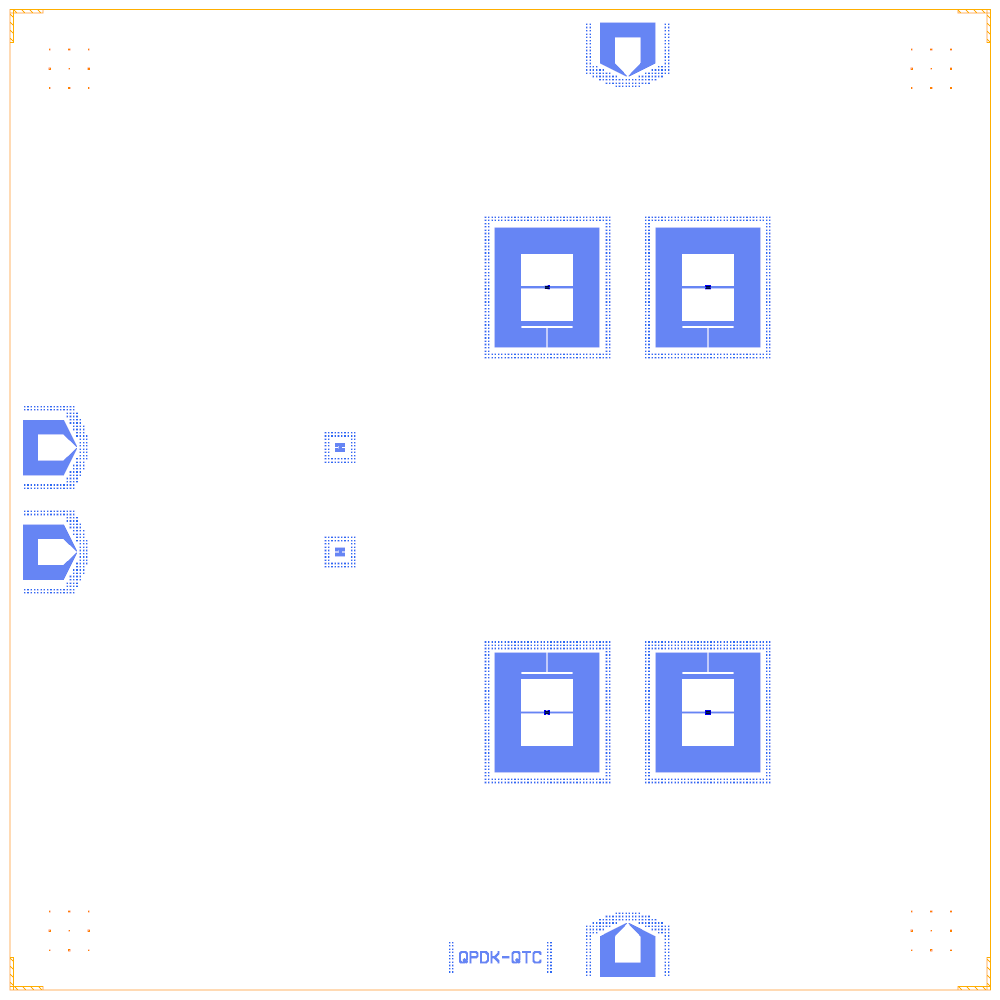

In [6]:
with d.batch():
    cin = d.add("C_IN", "FingerCapacitorSquare", at=(DX + 800, DY + 400), **QP.IDC)
    cout = d.add("C_OUT", "FingerCapacitorSquare", at=(DX + 800, DY - 400), **QP.IDC)
    q = {n: d.add(n, "DoublePads", at=(DX + x, DY + y), rot=r, junction=QP.JUNCTION, **QP.JJ_PARAMS, **QP.DOUBLE_PAD)
         for n, x, y, r in (("Q1", 2385, 1625, 180), ("Q2", 3615, 1625, 180),
                            ("Q3", 3615, -1627.421, 0), ("Q4", 2385, -1628.351, 0))}
print(q["Q1"])
snap(d, STEPS / "3_components.png", size=(1000, 1000), width=400);

## 6 · Routes

**Probeline:** launcher → C_IN → east, U-turn at x = 3415 µm (source), west → C_OUT → launcher (r = 100 µm,
QPDK's `cpw` bend radius). **Readouts:** each from the qubit's coupler plate, 900 µm west along the plate's line,
then a meander (r = 50 µm, 7 turns) to the coupled section, which hangs along the probeline at the source's
position and length — `fl.hanger(s=..., length=..., side="left", ground_gap=4, end="open")`: `s` is the
arclength along the probeline from its start at C_IN, `ground_gap` 4 µm is QPDK's 16 µm line-to-line gap
(26 − 5 − 6 − 6 − 5), `end="open"` keeps the λ/2. **Flux lines** from the top / bottom launchers to an open end
between the qubit pairs (source tee positions (3000, ±1775)).

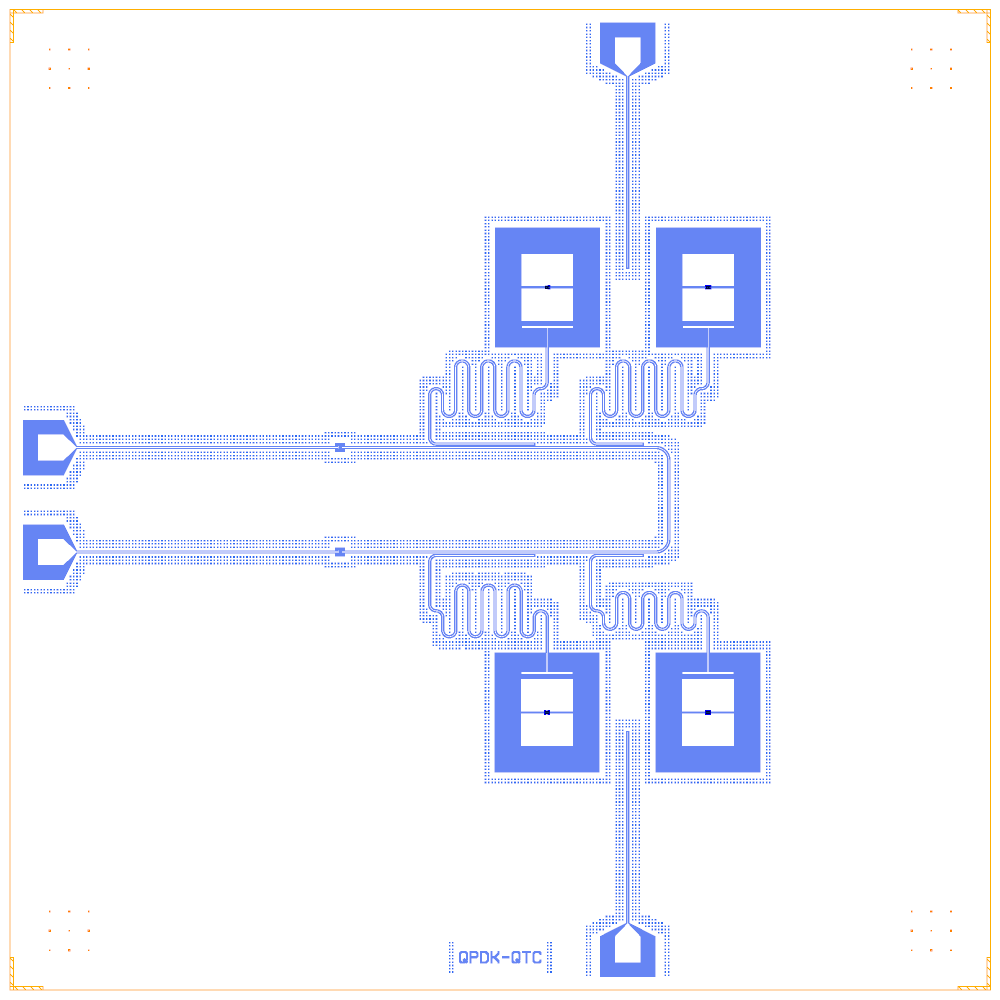

{'FL_IN': 1978.5, 'FL': 5671.2, 'FL_OUT': 1978.5, 'R1': 5000.0, 'R2': 4600.0, 'R3': 3600.0, 'R4': 4800.0, 'FLUX_T': 1465.0, 'FLUX_B': 1465.0}


In [7]:
with d.batch():
    d.route("FL_IN", pin.a, cin.a, r=QP.CPW_R)
    fl = d.route("FL", cin.b, cout.b, nodes=[(3415, DY + 400), (3415, DY - 400)], r=QP.CPW_R)
    d.route("FL_OUT", cout.a, pout.a, r=QP.CPW_R)
    x0 = 936.5                                         # FL starts at C_IN.b
    west = (3415 - x0) + 800                           # FL arclength at the start of the west-bound leg
    for n, qn, s, way, L, total, y in (("R1", "Q1", 1985 - x0, "forward", 800, 5000, 3950),
                                       ("R2", "Q2", 3015 - x0, "forward", 400, 4600, 3950),
                                       ("R3", "Q3", west + 3415 - 3015, "backward", 400, 3600, 2250),
                                       ("R4", "Q4", west + 3415 - 1985, "backward", 800, 4800, 2250)):
        xq = d.data["instances"][qn]["place"]["at"][0]
        d.route(n, q[qn].cplr, fl.hanger(s=s, length=L, side="left", ground_gap=QP.HANGER_GROUND_GAP, direction=way,
                                         end="open"),
                meander=total, r=50, nodes=[(xq, y), (xq - 900, y)]).set(meanders=7)
    d.route("FLUX_T", pft.a, Designer.free_end((DX + 3000, DY + 1775), dir=90, term=6), r=QP.CPW_R)
    d.route("FLUX_B", pfb.a, Designer.free_end((DX + 3000, DY - 1775), dir=270, term=6), r=QP.CPW_R)
snap(d, STEPS / "4_routes.png", size=(1000, 1000), width=400)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

**Centring.** `pdk_report` measures the content centre over everything placed, pads included, so the whole layout is
centred, not only the circuit. The probeline pads sit 100 µm (`frame.pad_edge`) from the west die edge
(`edge="auto"`), which fixes the west side of the content, so `QP.center_content` shifts the circuit east until the
content box's centre is the die centre (to 0.5 µm). Each pad keeps its 100 µm and slides only along its edge: the
west pads follow the shift in y, the top / bottom flux pads in x (their edge is fixed first, so a pad that slides far
along an edge does not switch to another one). Here the circuit moves **+1660 µm** in x from the source frame (the circuit-only centring
of earlier versions stopped 2024 µm short of that). The circuit's east side (the Q2 / Q3 pockets) then sits exactly on the
design-area margin, 100 µm from the east die edge: the DRC raises no `frame_margin` / `frame_keepout` warning and the
PDK cheese band still fits (its holes stop 10 µm inside the margin). The price: the probeline leads from the pads to
the IDCs are 3638.5 µm long (were 1614.3 µm); the readouts, the probeline and the qubits are unchanged, and so is the LOM (the
leads are outside the sim groups). Then the design is saved: the JSON is what DRC, LOM, FEM and `qcc` read.
**Sim groups:** one per qubit with its readout and the probeline (Q3D C-matrix + eigenmode/EPR, 150 µm margin).

In [8]:
for i in range(1, 5):
    d.sim_group(f"Q{i}R{i}", [f"Q{i}", f"R{i}", "FL"], margin_um=150)
SHIFT = QP.center_content(d)                  # the whole layout (pads included) centred, pads stay on their edges
print("centring shift of the circuit (µm):", SHIFT)
rebuild(d)
print("lead lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items() if k in ("FL_IN", "FL_OUT", "FLUX_T", "FLUX_B")})
DESIGN = d.save(OUT / "qubit_test_chip.json")
print(d, "→", DESIGN)

centring shift of the circuit (µm): (1660.0, 0.0)


lead lengths (µm): {'FL_IN': 3638.5, 'FL_OUT': 3638.5, 'FLUX_T': 1465.0, 'FLUX_B': 1465.0}
<Designer qubit_test_chip: 10 instances, 9 routes, live=False> → examples\designs\qpdk\qubit_test_chip.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced — the rebuild keeps the source's choices. `pdk_report` adds the
cheese source, the centring (of everything, pads included: it reads (+0, +0) µm after step 6's `QP.center_content`)
and the junction types.
Here: four `dangling_port` warnings (the DoublePads `drive` ports — QPDK's qubits have no drive line) and no PDK
design warning: the pads are 100 µm from the edge (the rule), and each SQUID's R_n (the parallel R_n of its two 90 kΩ
junctions, 45 kΩ) is inside the 40–50 kΩ window.

In [9]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 4 | Q1.drive is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 4 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit
nodes, routes join nodes (or become transmission-line resonators), pads are 50 Ω ports, flux / gate lines
are controls. The first table lists the nodes and the FEM nets that form each one, the second the
branches with their component estimates; the last one maps a few ports to their nodes.
The `DoublePads` model: two pad nodes (C between them = the shunt, C of each pad to ground, the SQUID across the
gap) and a coupler node on the plate; each readout route with its open hanger is a λ/2 `TLres` from the coupler
node, coupled to the probeline node by a `HANGER` κ element; the probeline between the IDCs is one node with the
two 50 Ω pads beyond the IDCs. The flux lines end open beside the qubits (QPDK's tee stubs), not on a
SQUID port, so the LOM has no flux control for them (0 controls; the unused `drive` ports map to a drive control).

In [10]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(('Q1.', 'R1', 'C_IN',)))))

**18 nodes · 44 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `C_IN.a` | `PAD_IN.pad`, `C_IN.a` |
| `C_OUT.a` | `PAD_OUT.pad`, `C_OUT.a` |
| `PAD_FT.pad` | `PAD_FT.pad` |
| `PAD_FB.pad` | `PAD_FB.pad` |
| `C_IN.b` | `C_IN.b`, `C_OUT.b` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.cplr` | `Q1.cplr` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.cplr` | `Q2.cplr` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.cplr` | `Q3.cplr` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |
| `Q4.cplr` | `Q4.cplr` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_IN` | R | `C_IN.a` – `gnd` | 50 Ω |
| `Port_PAD_OUT` | R | `C_OUT.a` – `gnd` | 50 Ω |
| `Port_PAD_FT` | R | `PAD_FT.pad` – `gnd` | 50 Ω |
| `Port_PAD_FB` | R | `PAD_FB.pad` – `gnd` | 50 Ω |
| `C_C_IN` | C | `C_IN.a` – `C_IN.b` | 6.12 fF |
| `C_C_IN_a` | C | `C_IN.a` – `gnd` | 2.7 fF |
| `C_C_IN_b` | C | `C_IN.b` – `gnd` | 2.7 fF |
| `C_C_OUT` | C | `C_OUT.a` – `C_IN.b` | 6.12 fF |
| `C_C_OUT_a` | C | `C_OUT.a` – `gnd` | 2.7 fF |
| `C_C_OUT_b` | C | `C_IN.b` – `gnd` | 2.7 fF |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 72.4 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 72.4 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 48.1 fF |
| `J_Q1` | SQUID | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_cplr` | C | `Q1.island1` – `Q1.cplr` | 33.1 fF |
| `Cc_Q1_cplr` | C | `Q1.cplr` – `gnd` | 18 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 72.4 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 72.4 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 48.1 fF |
| `J_Q2` | SQUID | `Q2.island1` – `Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_cplr` | C | `Q2.island1` – `Q2.cplr` | 33.1 fF |
| `Cc_Q2_cplr` | C | `Q2.cplr` – `gnd` | 18 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 72.4 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 72.4 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 48.1 fF |
| `J_Q3` | SQUID | `Q3.island1` – `Q3.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_cplr` | C | `Q3.island1` – `Q3.cplr` | 33.1 fF |
| `Cc_Q3_cplr` | C | `Q3.cplr` – `gnd` | 18 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 72.4 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 72.4 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 48.1 fF |
| `J_Q4` | SQUID | `Q4.island1` – `Q4.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_cplr` | C | `Q4.island1` – `Q4.cplr` | 33.1 fF |
| `Cc_Q4_cplr` | C | `Q4.cplr` – `gnd` | 18 fF |
| `R1` | TLres | `Q1.cplr` – `gnd` | lambda/2, 5000 µm, 12.603 GHz |
| `K_R1` | HANGER | `Q1.cplr` – `C_IN.b` | κ 0.814 MHz (L 800 µm) |
| `R2` | TLres | `Q2.cplr` – `gnd` | lambda/2, 4600 µm, 13.699 GHz |
| `K_R2` | HANGER | `Q2.cplr` – `C_IN.b` | κ 0.265 MHz (L 400 µm) |
| `R3` | TLres | `Q3.cplr` – `gnd` | lambda/2, 3600 µm, 17.505 GHz |
| `K_R3` | HANGER | `Q3.cplr` – `C_IN.b` | κ 0.551 MHz (L 400 µm) |
| `R4` | TLres | `Q4.cplr` – `gnd` | lambda/2, 4800 µm, 13.129 GHz |
| `K_R4` | HANGER | `Q4.cplr` – `C_IN.b` | κ 0.918 MHz (L 800 µm) |
| `FLUX_T` | TLres | `PAD_FT.pad` – `gnd` | lambda/2, 1465 µm, 43.015 GHz |
| `FLUX_B` | TLres | `PAD_FB.pad` – `gnd` | lambda/2, 1465 µm, 43.015 GHz |

**Unconnected ports:** none

**Builder notes:**

- Q1: floating transmon; island2 ↔ coupler capacitance neglected (screened by island1)
- Q2: floating transmon; island2 ↔ coupler capacitance neglected (screened by island1)
- Q3: floating transmon; island2 ↔ coupler capacitance neglected (screened by island1)
- Q4: floating transmon; island2 ↔ coupler capacitance neglected (screened by island1)

**Ports → circuit nodes:**

| port | node |
|---|---|
| `C_IN.a` | `C_IN.a` |
| `C_IN.b` | `C_IN.b` |
| `Q1.cplr` | `Q1.cplr` |
| `Q1.drive` | `control:drive` |

## 9 · LOM simulation

Each group holds one qubit, its λ/2 readout and the probeline (the two series IDCs are outside the selection, so
the probeline ends in its 50 Ω ports): QuCat normal modes and κ, then the QuTiP-dressed f_q, α, f_r and χ. The
source states no targets; with the PDK SQUIDs f_q ≈ 5.8 GHz is expected (the earlier 11 nH stand-in gave
4.75 GHz).

In [11]:
groups = {f"Q{i}R{i}": [f"Q{i}", f"R{i}", "FL"] for i in range(1, 5)}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1R1 | Q1 | 5.7631 | -196.5 | R1 | 11.866 | 0.638 | -1.36 |
| Q2R2 | Q2 | 5.7635 | -196.6 | R2 | 12.862 | 0.206 | -1.27 |
| Q3R3 | Q3 | 5.7645 | -196.9 | R3 | 16.165 | 0.4 | 1.61 |
| Q4R4 | Q4 | 5.7633 | -196.6 | R4 | 12.33 | 0.713 | -1.31 |

## 10 · FEM: send the jobs
Per qubit / readout pair a Q3D C-matrix job and an eigenmode / EPR job (the probeline leaving the box ends in 50 Ω, so the eigenmode Q gives κ).
Each sim group is cut out of the chip with its margin; every line leaving the box ends in a port, a
junction is a lumped port, and the cheese is never exported (simulation exports have none). The table
lists each job's ports and C-matrix nets (named after the islands, couplers and routes, so a result maps
back onto the LOM nodes). With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs`
solves each Ansys job in a **new batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open
is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [12]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

8 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 · eigenmode_epr | `build/jobs/qubit_test_chip_Q1R1_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `FLUX_T`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R2`<br>6 · edge_lumped · `R3`<br>7 · edge_lumped · `R4` | `Q1.island1`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R2`, `R3`, `R4`, `FL`, `Q1.cplr`, `Q1.island2` |
| Q1R1 · q3d_cmatrix | `build/jobs/qubit_test_chip_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.cplr`<br>3 · edge · `FLUX_T`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R2`<br>7 · edge · `R3`<br>8 · edge · `R4` | `Q1.island1`, `Q1.cplr`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R2`, `R3`, `R4`, `FL`, `Q1.island2` |
| Q2R2 · eigenmode_epr | `build/jobs/qubit_test_chip_Q2R2_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `FLUX_T`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R3`<br>6 · edge_lumped · `R4` | `Q2.island1`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R3`, `R4`, `FL`, `R1`, `Q2.cplr`, `floating`, `Q2.island2` |
| Q2R2 · q3d_cmatrix | `build/jobs/qubit_test_chip_Q2R2_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.cplr`<br>3 · edge · `FLUX_T`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R3`<br>7 · edge · `R4` | `Q2.island1`, `Q2.cplr`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R3`, `R4`, `FL`, `R1`, `floating`, `Q2.island2` |
| Q3R3 · eigenmode_epr | `build/jobs/qubit_test_chip_Q3R3_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · edge_lumped · `FLUX_B`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R1`<br>6 · edge_lumped · `R2` | `Q3.island1`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `Q3.island2`, `floating`, `R4`, `Q3.cplr`, `FL` |
| Q3R3 · q3d_cmatrix | `build/jobs/qubit_test_chip_Q3R3_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.cplr`<br>3 · edge · `FLUX_B`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R1`<br>7 · edge · `R2` | `Q3.island1`, `Q3.cplr`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `Q3.island2`, `floating`, `R4`, `FL` |
| Q4R4 · eigenmode_epr | `build/jobs/qubit_test_chip_Q4R4_eigenmode_epr` | 1 · junction · `Q4.junction`<br>2 · edge_lumped · `FLUX_B`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R1`<br>6 · edge_lumped · `R2`<br>7 · edge_lumped · `R3` | `Q4.island1`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `R3`, `Q4.island2`, `Q4.cplr`, `FL` |
| Q4R4 · q3d_cmatrix | `build/jobs/qubit_test_chip_Q4R4_q3d_cmatrix` | 1 · junction · `Q4.junction`<br>2 · waveguide · `Q4.cplr`<br>3 · edge · `FLUX_B`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R1`<br>7 · edge · `R2`<br>8 · edge · `R3` | `Q4.island1`, `Q4.cplr`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `R3`, `Q4.island2`, `FL` |

## 11 · Bring the results back

A solved job holds `results/results.json`. `fem_back` then calls `fill(model, design, job)`: the C-matrix
(or eigenmode) values replace the component estimates branch by branch, matched by net name, and the table
compares the two; `simulate(filled)` re-runs the LOM on the extracted values. Until then the cell says which
jobs are still waiting.

In [13]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for Q1R1 · eigenmode_epr, Q1R1 · q3d_cmatrix, Q2R2 · eigenmode_epr, Q2R2 · q3d_cmatrix, Q3R3 · eigenmode_epr, Q3R3 · q3d_cmatrix, Q4R4 · eigenmode_epr, Q4R4 · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

Shorten readout R1 from 5000 to 4500 µm: the λ/2 line's f_r rises (≈ 10 %), the qubit–readout detuning grows and
|χ| drops. The change is made on a copy (`design_copy`), so `qubit_test_chip.json` keeps the source's length.

In [14]:
d2 = design_copy(DESIGN)
d2["R1"].set(meander=4500)
after = simulate_groups(d2, {"Q1R1": groups["Q1R1"]})
display(Markdown("**R1: 5000 → 4500 µm**\n\n" + params_delta_md({"Q1R1": res["Q1R1"]}, after)))

**R1: 5000 → 4500 µm**

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1R1: Q1.f_q_GHz` | 5.7631 | 5.7636 | +0.0005445 |
| `Q1R1: Q1.alpha_MHz` | -196.51 | -196.67 | -0.1553 |
| `Q1R1: R1.chi_MHz` | -1.3632 | -1.2451 | +0.1181 |
| `Q1R1: R1.f_GHz` | 11.866 | 13.1 | +1.234 |
| `Q1R1: R1.kappa_MHz` | 0.63807 | 0.84912 | +0.2111 |

## 13 · Build and export

**The design file.** `qubit_test_chip.json` (saved in step 6) is the whole design: `qcc build
examples/designs/qpdk/qubit_test_chip.json` rebuilds `build/qubit_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the
filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers
2/0 + 4/0 and spacer 50/0 with the 51–53/0 dose gradient, flip-chip 800+/0 where used, and the frame
(100/0, 1000/0, 1001/0).
The cheese source is `build`: the PDK band drawn in the build (the source has none), 5 µm holes on a 25 µm
pitch, three rows around every 3/0 keep-out and at least 4 µm clear of it.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/qubit_test_chip.json`
writes the complete file.

In [15]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 7750 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 7741 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 16 |
| 51/0 | SPACER_1 | 16 |
| 52/0 | SPACER_2 | 16 |
| 53/0 | SPACER_3 | 16 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 7735 holes on the mask.

→ `build/qubit_test_chip_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed
unless `airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says
what the export left out (this chip has no airbridges, so both settings give the same geometry).

In [16]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

The full die (compare QPDK's `qubit_test_chip.png`, shown last); qubit Q1 with its coupler plate; its SQUID gap;
the R1 coupled section on the probeline; the input IDC; the top flux-line end; the die frame's south-west corner
(dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); and Q1 in the **fab view** (the mask from step 13: 1/0
with the PDK cheese band, 3/0, the trilayer layers). Boxes are the source positions + the centring shift. In the
layout snapshots the chip boundary 100/0 is drawn as an outline and the cheese band (KQC's ground-grid layer) is
visible; the fab view shows the mask itself.

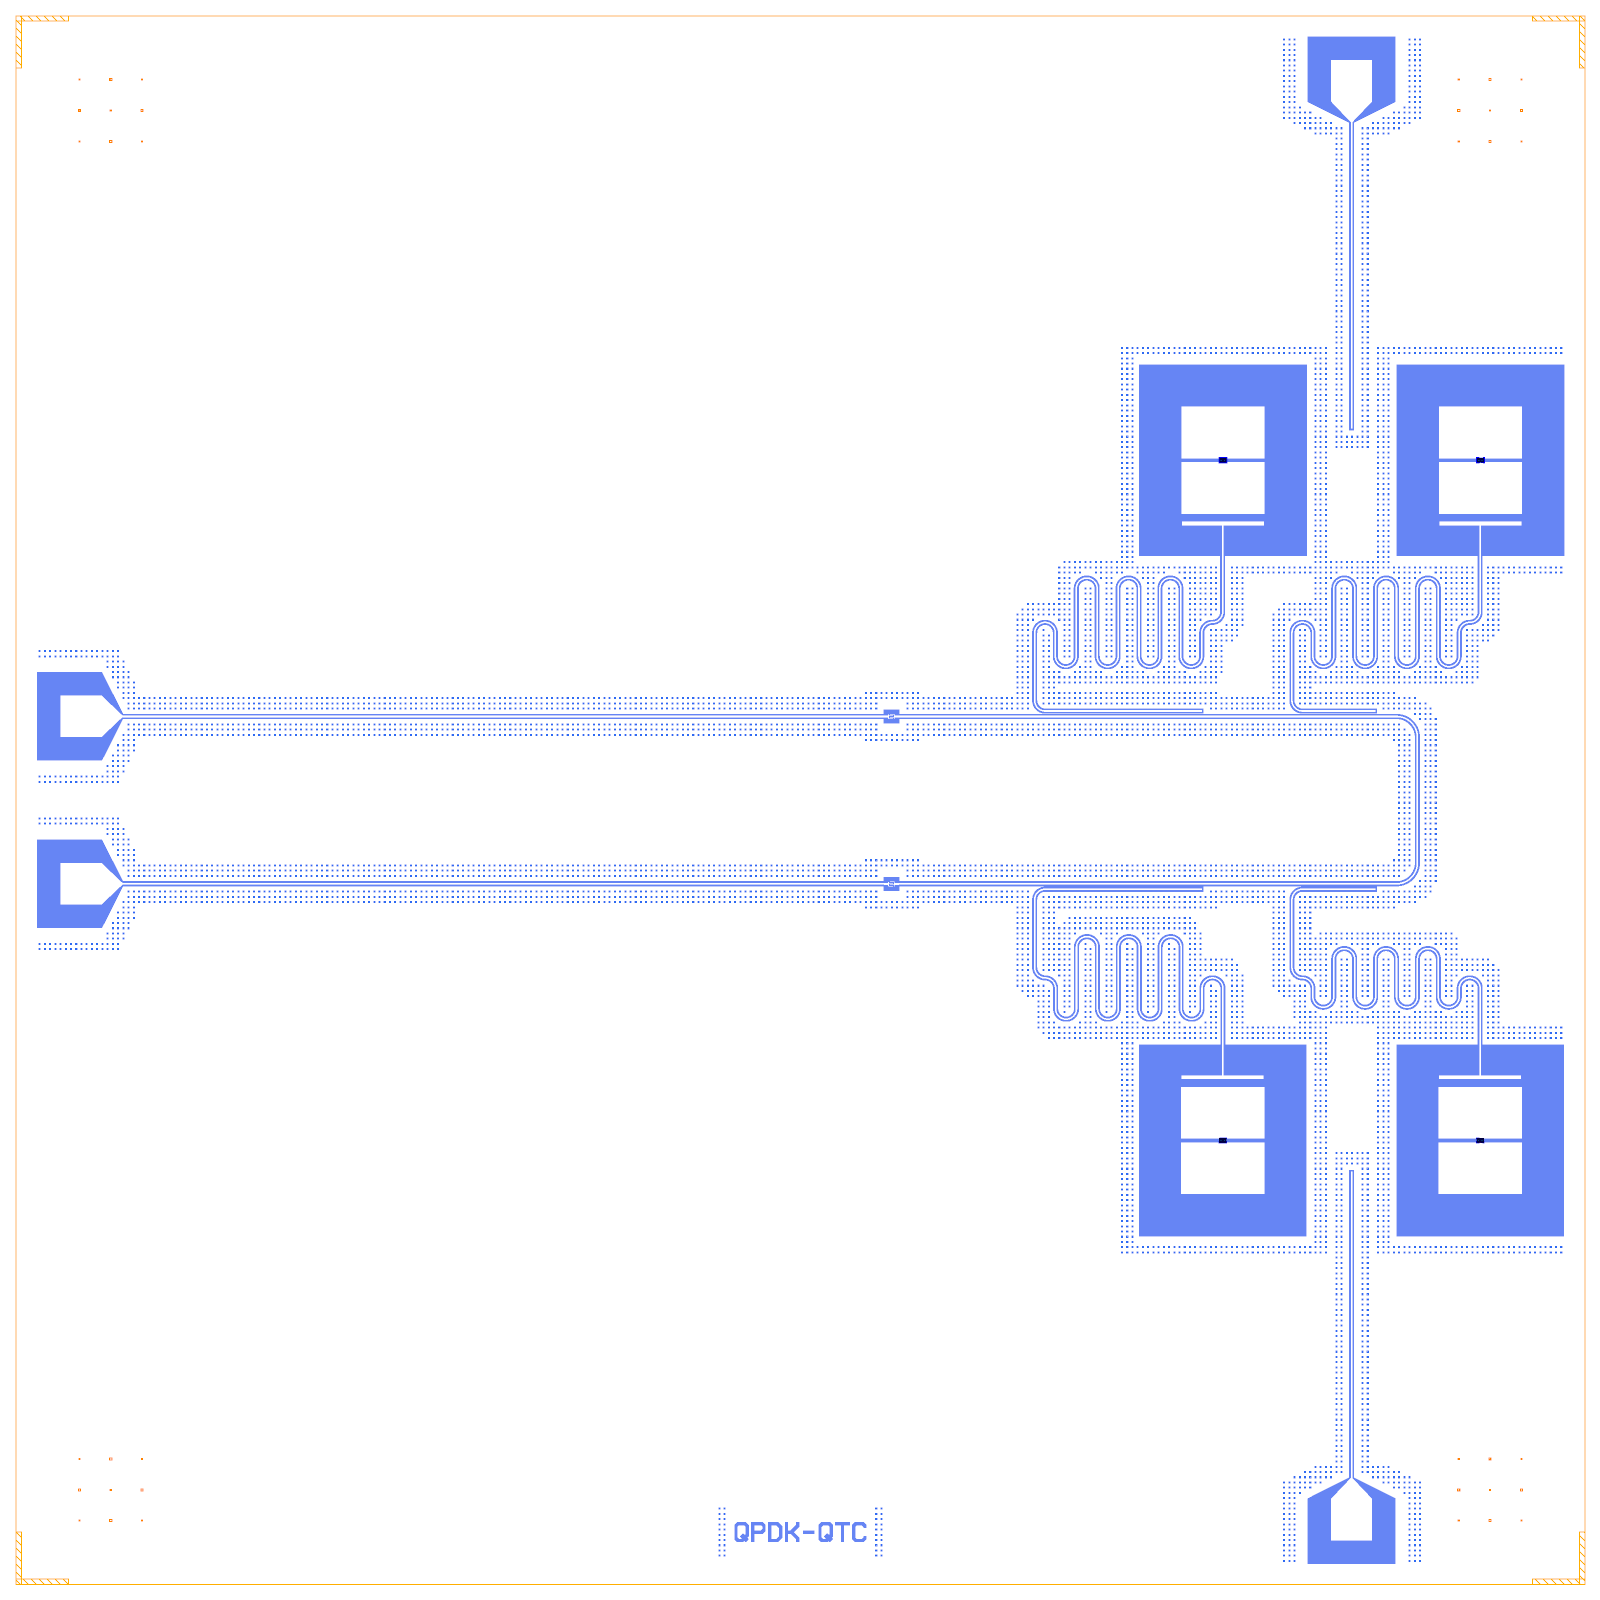

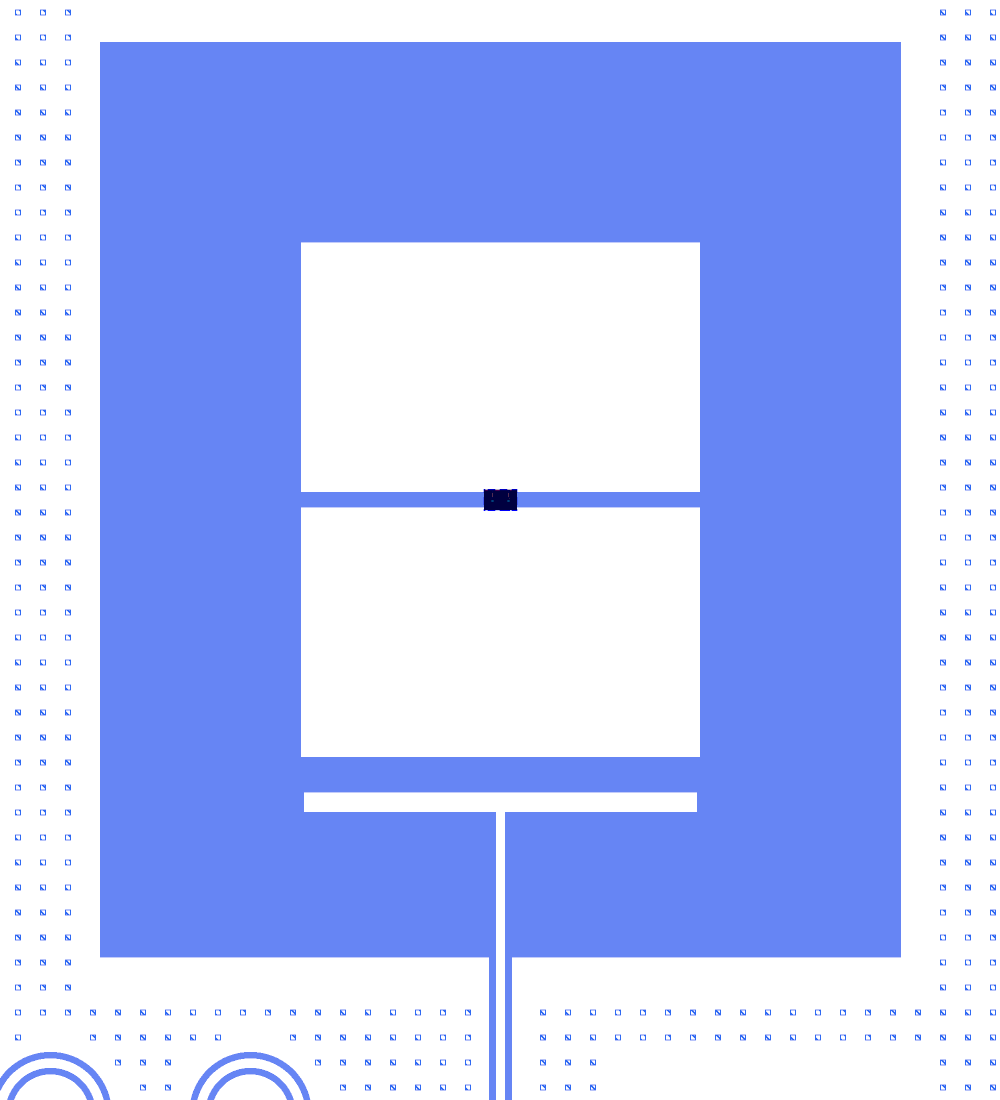

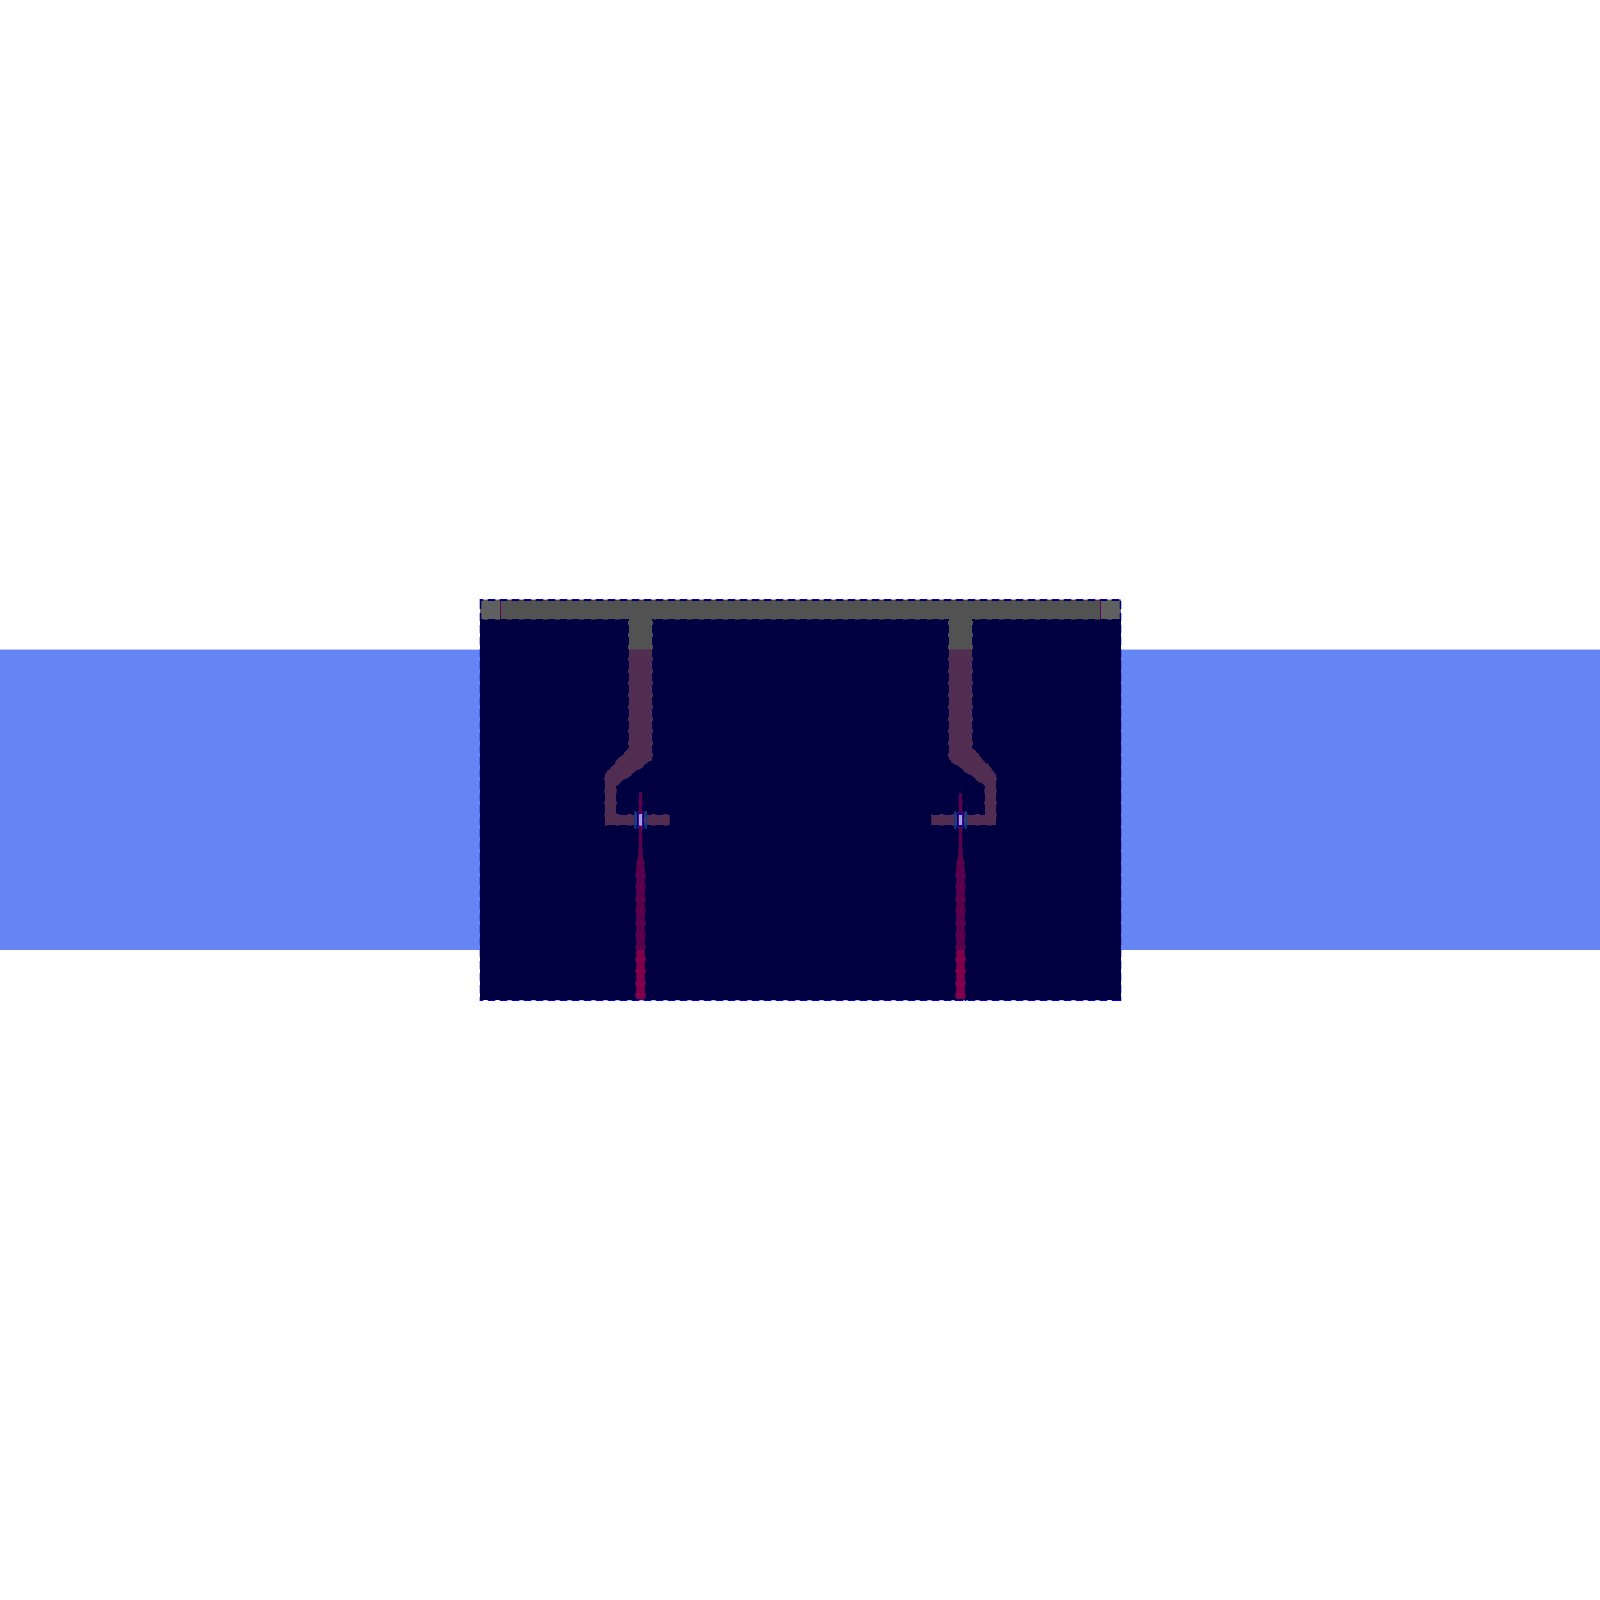

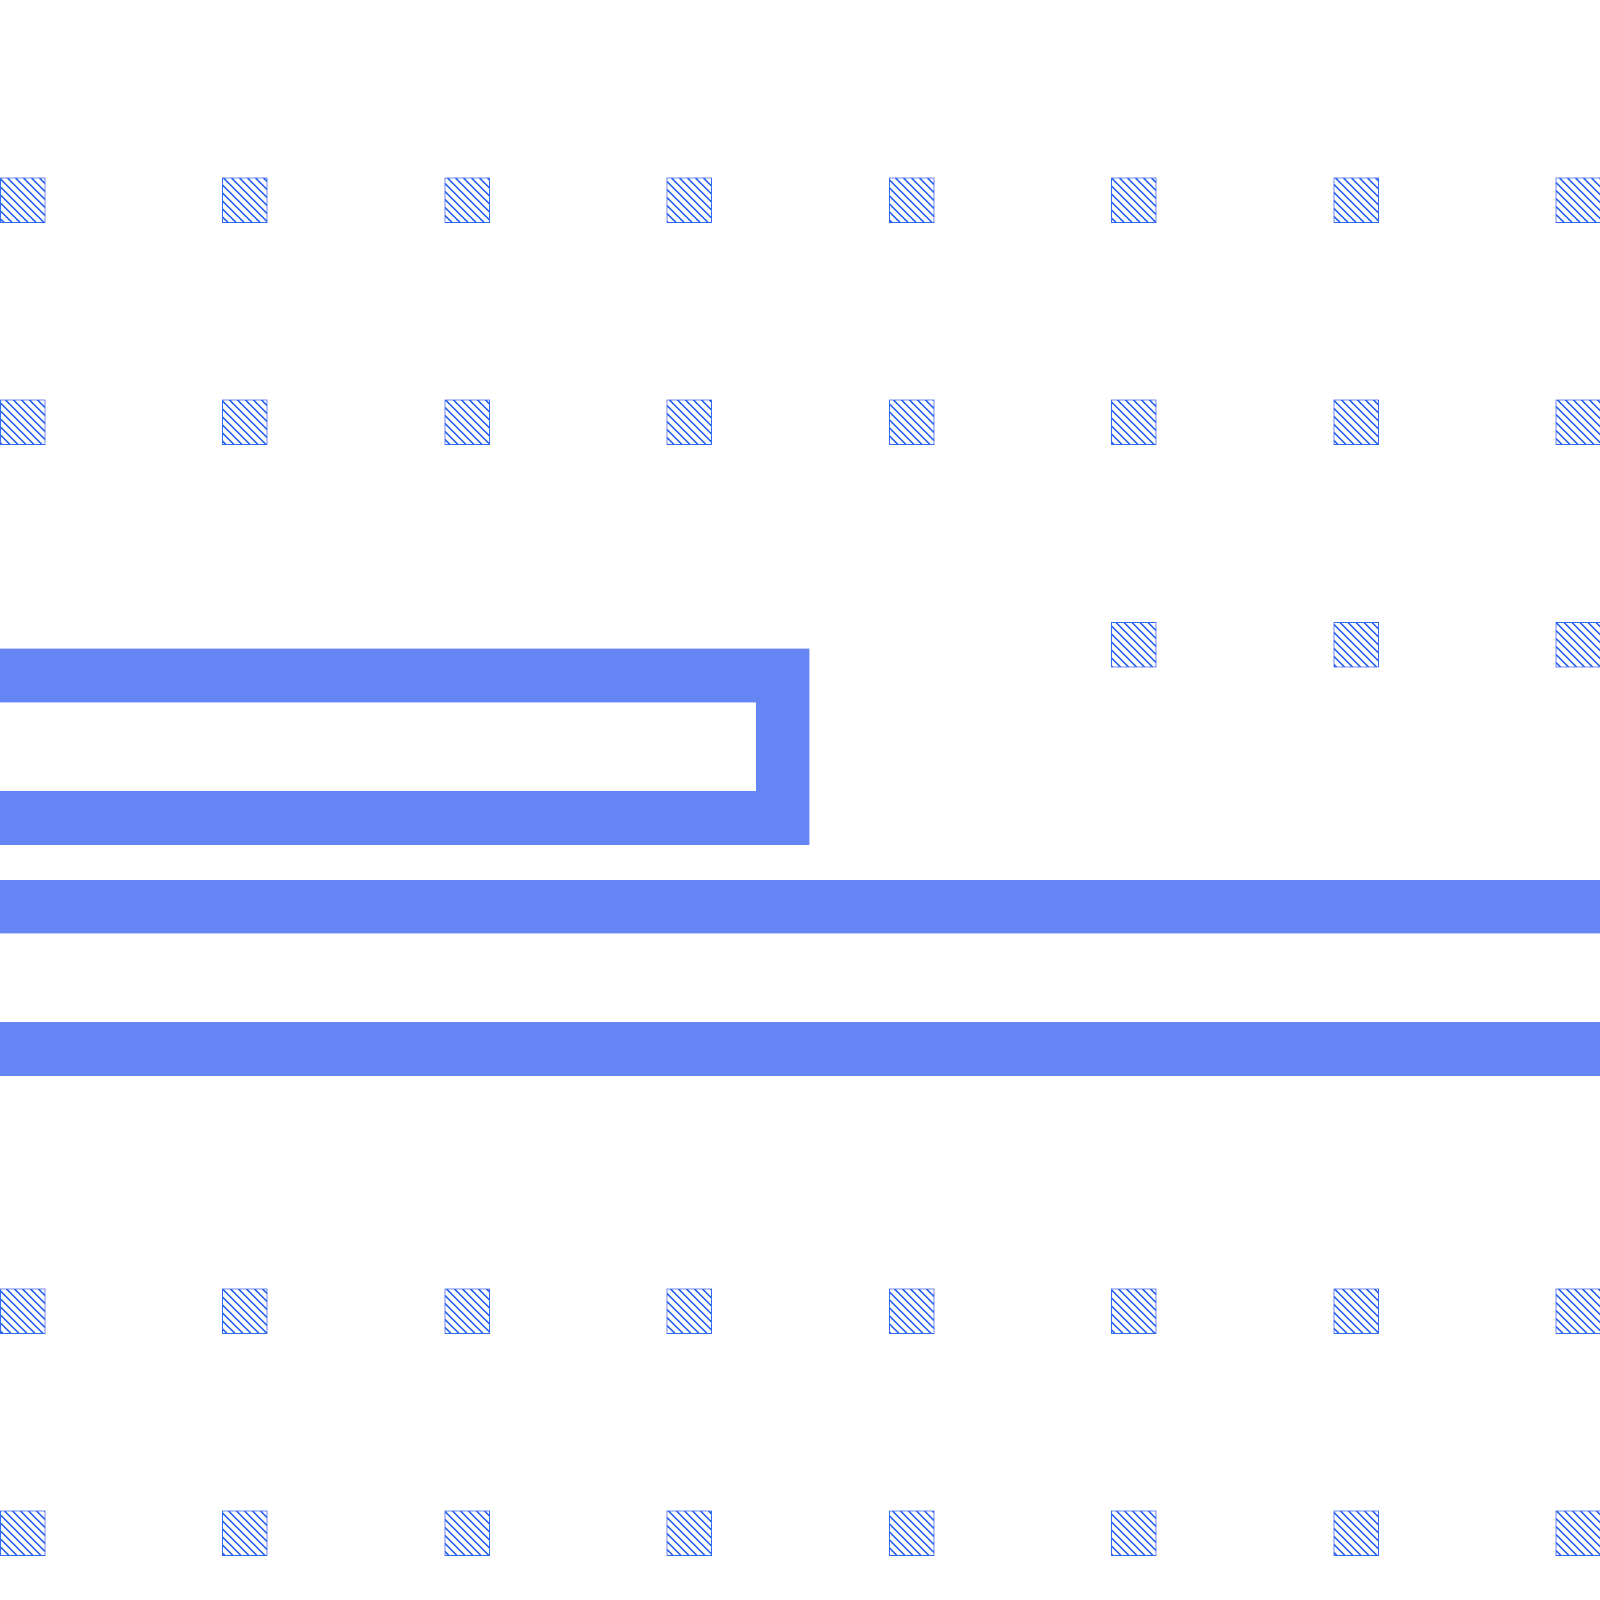

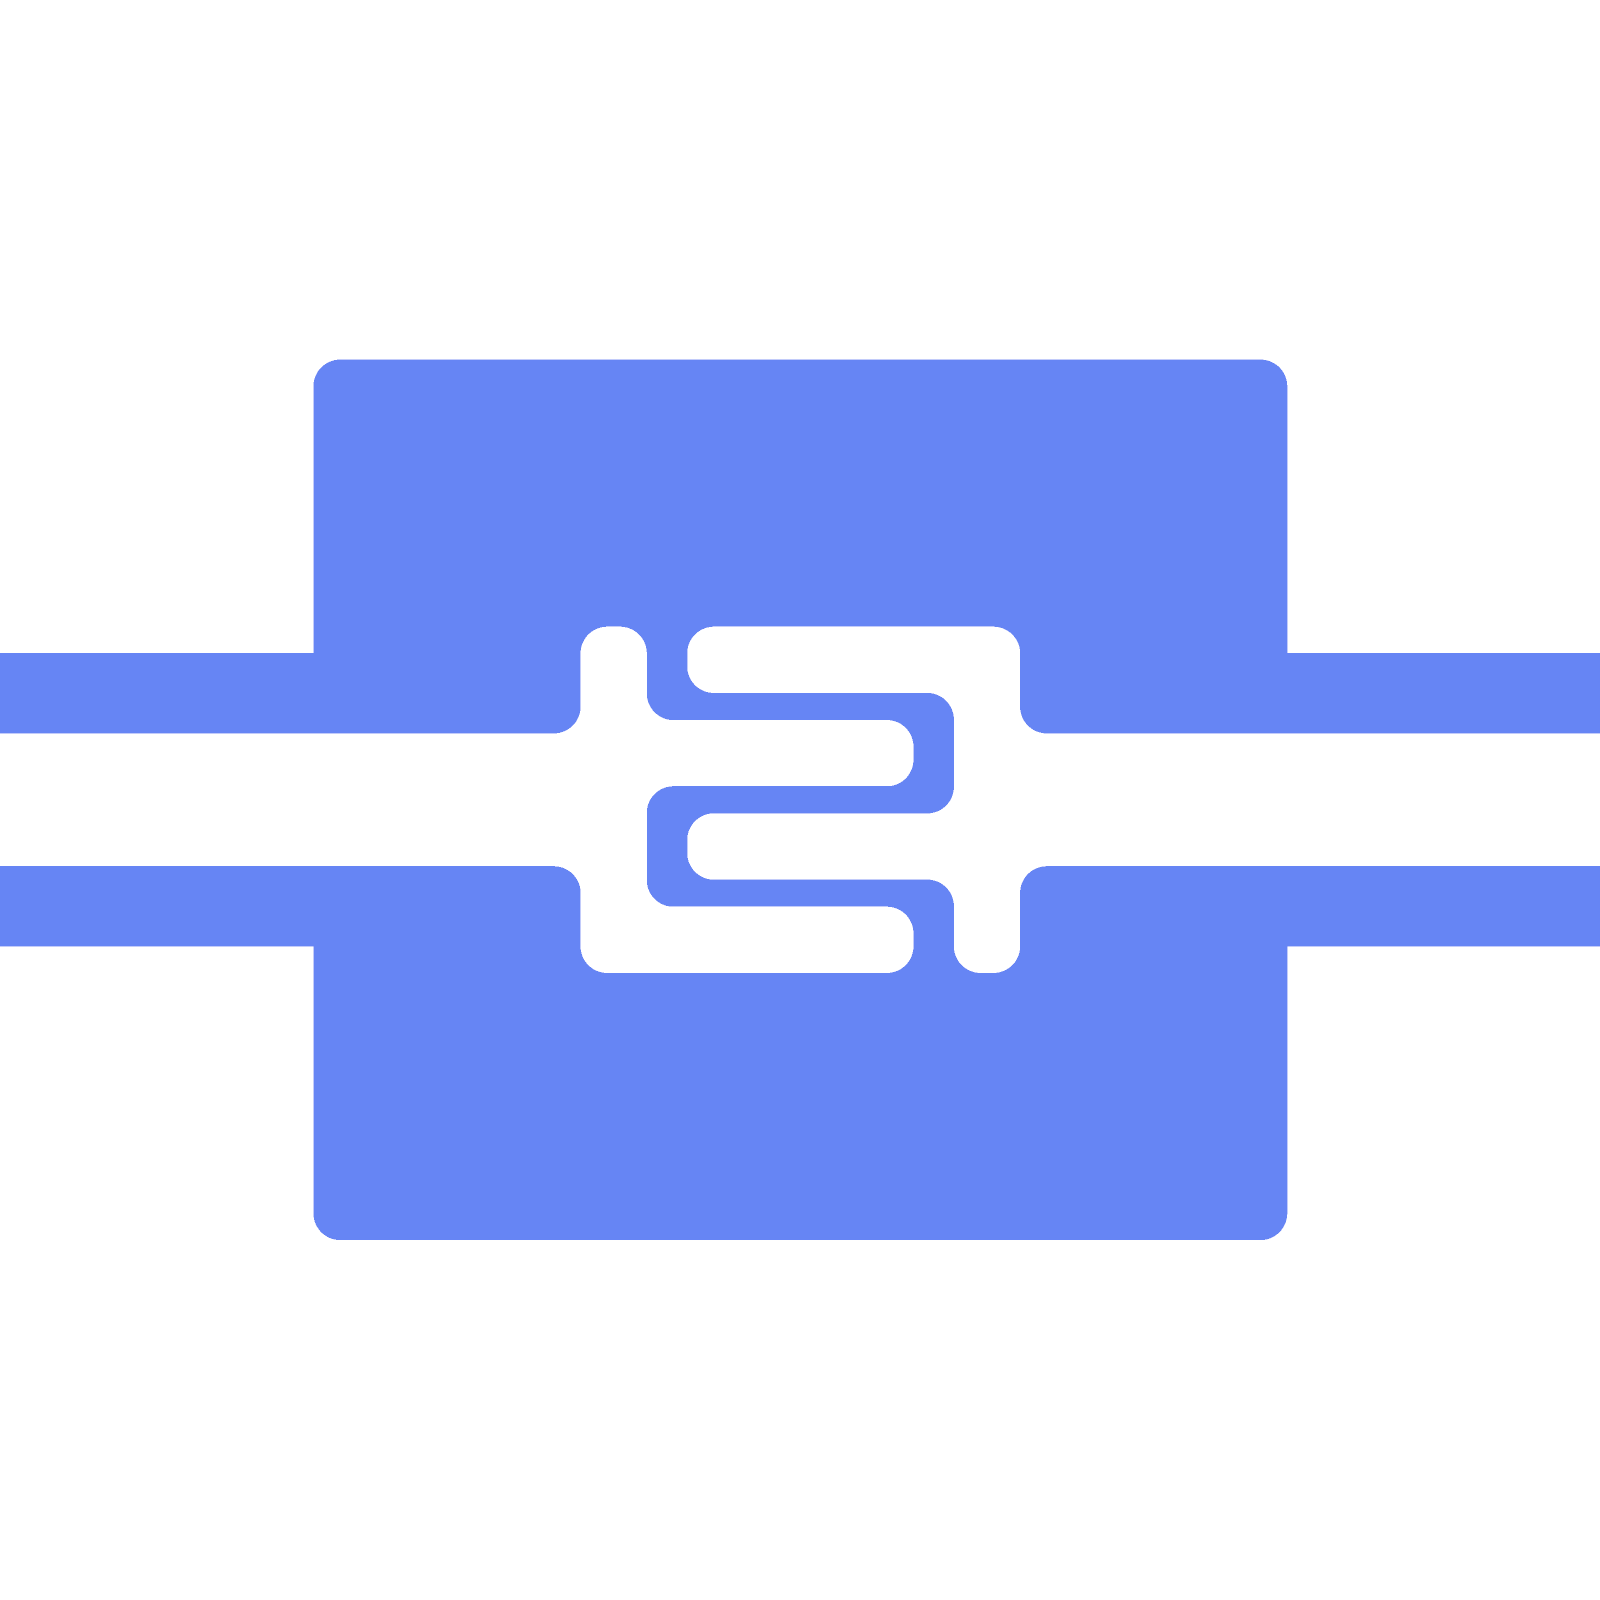

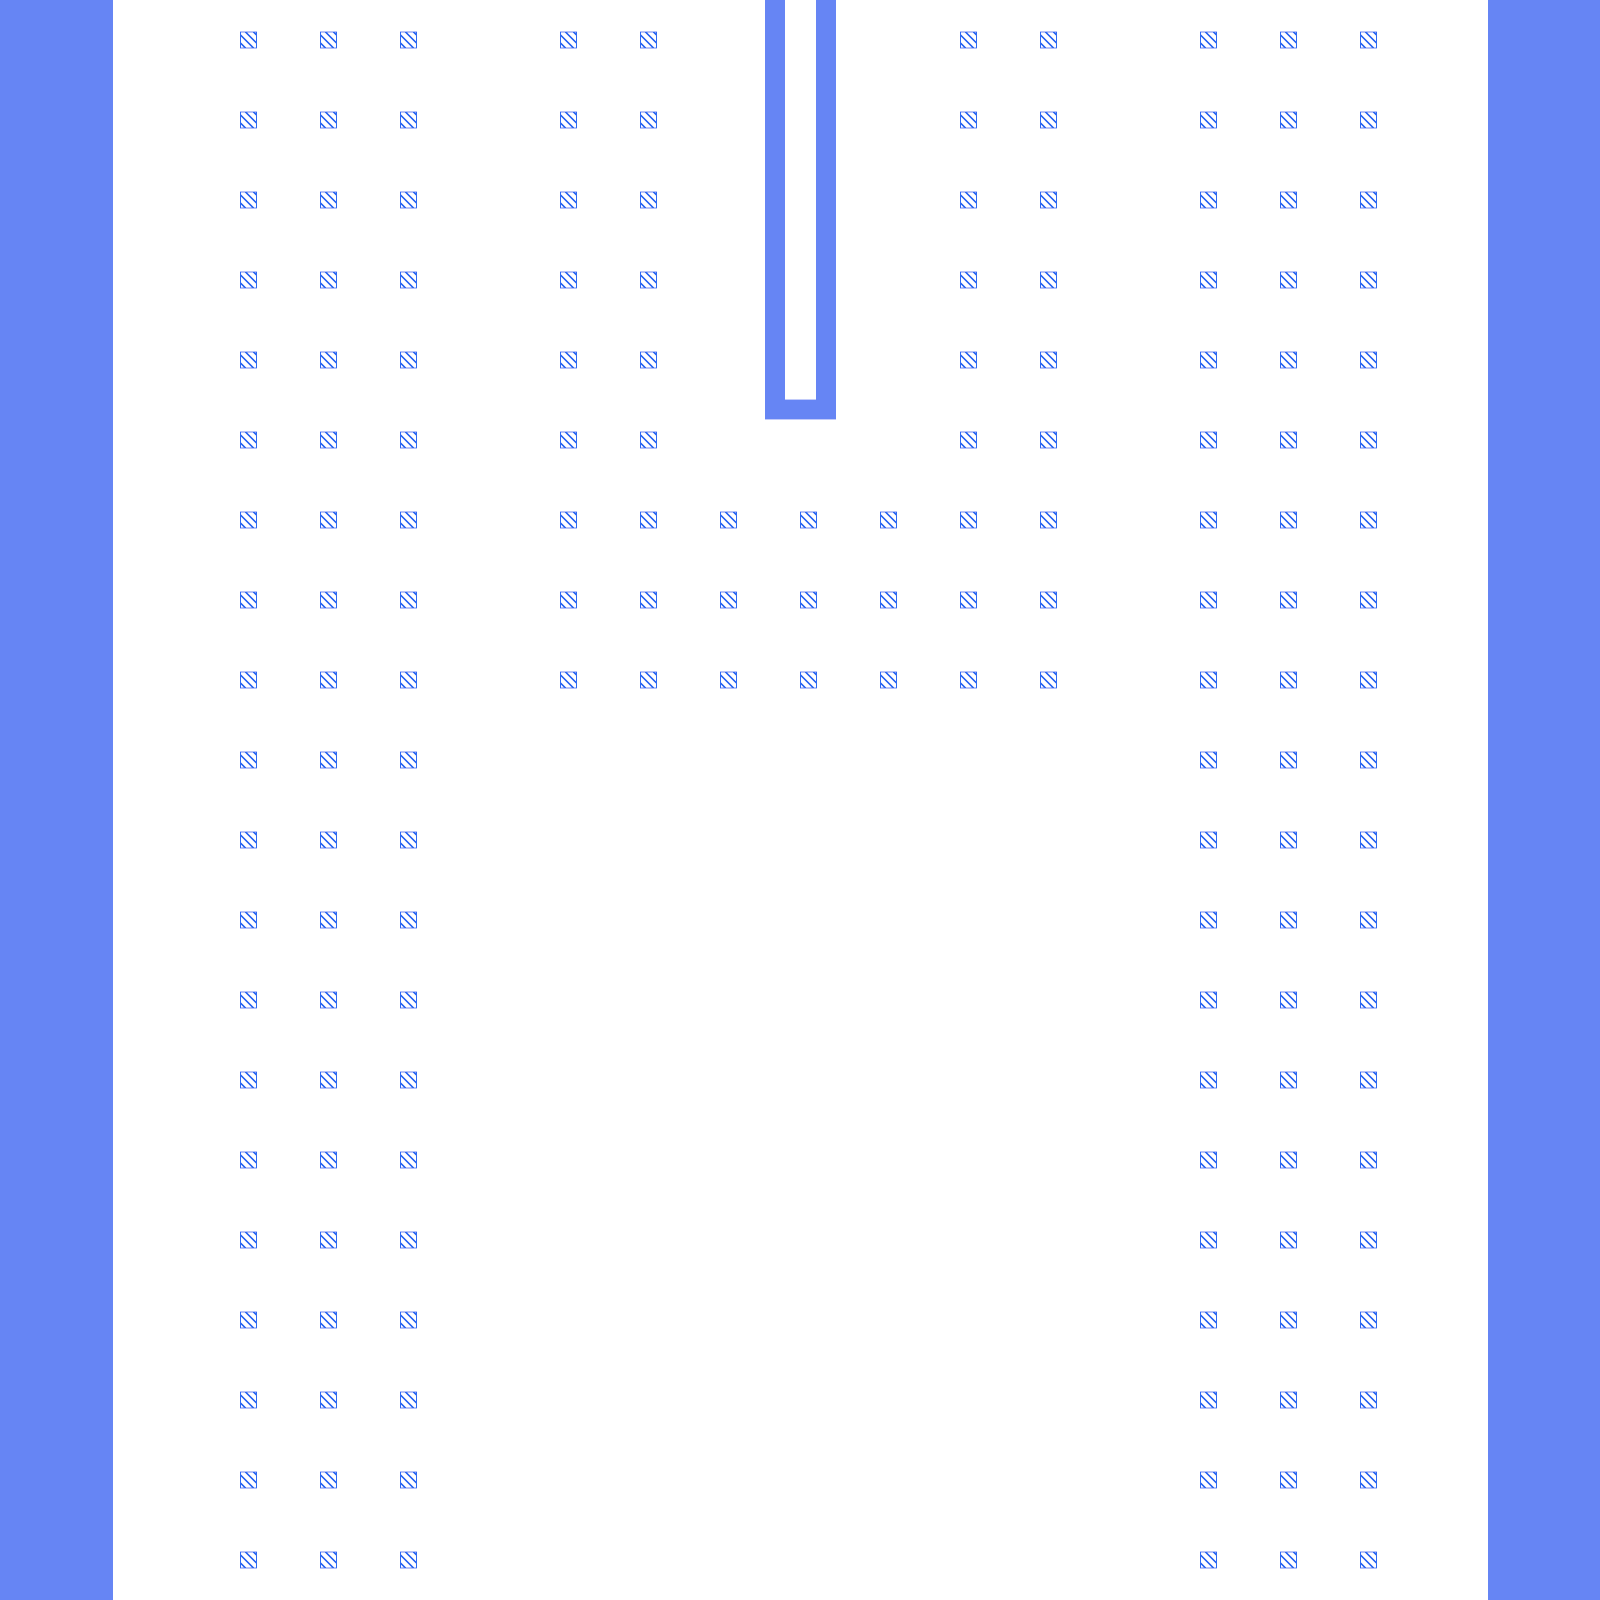

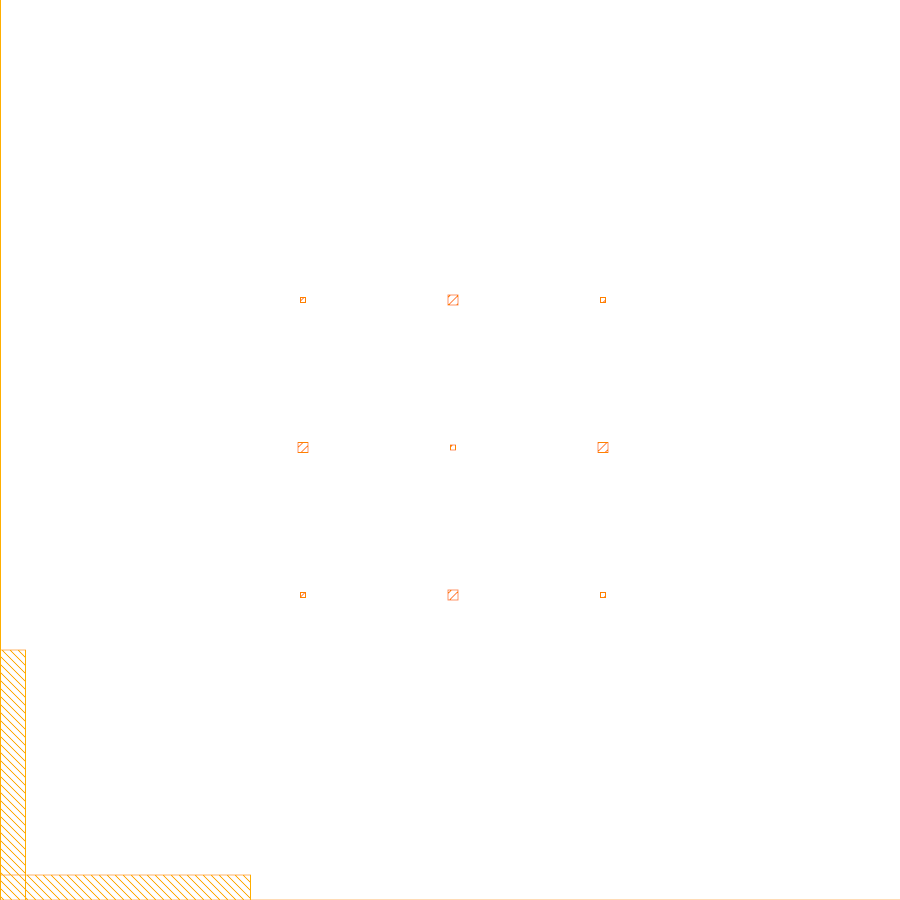

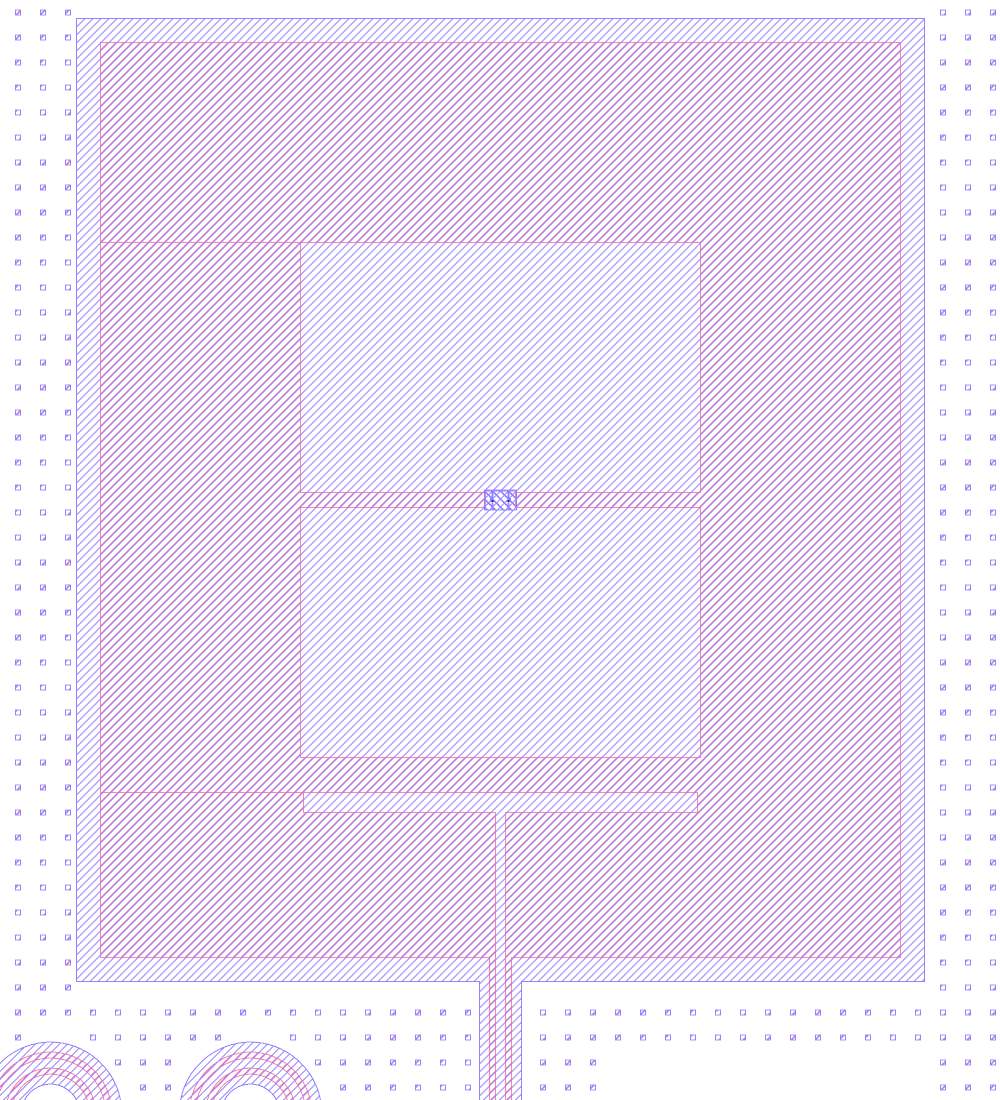

In [17]:
SX, SY = SHIFT


def box(x0, y0, x1, y1):                         # a source-frame box, moved with the centring shift
    return (x0 + SX, y0 + SY, x1 + SX, y1 + SY)


show_snapshot(d, OUT / "qubit_test_chip.png", size=(1600, 1600))
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / "qubit_test_chip_q1.png", box=(qx - 500, qy - 600, qx + 500, qy + 500), size=(1000, 1100), width=420)
show_snapshot(d, OUT / "qubit_test_chip_squid.png", box=(qx - 40, qy - 40, qx + 40, qy + 40), width=300)
show_snapshot(d, OUT / "qubit_test_chip_coupler.png", box=box(2300, 3440, 2480, 3600), width=360)
show_snapshot(d, OUT / "qubit_test_chip_idc.png", box=box(840, 3460, 960, 3540), width=360)
show_snapshot(d, OUT / "qubit_test_chip_flux.png", box=box(2900, 4500, 3300, 5000), width=360)
show_snapshot(d, OUT / "qubit_test_chip_frame.png", box=(-1625, -650, -725, 250), size=(900, 900), width=300)
snap_file(Path("build") / "qubit_test_chip_fab.oas", OUT / "qubit_test_chip_fab_q1.png",
          box=(qx - 500, qy - 600, qx + 500, qy + 500), size=(1000, 1100), width=420);

**The original.** gdsfactory (QPDK's layout engine) is not installed in this environment, so the source is not
rebuilt here; QPDK's own render of the chip is shown from the local clone when present.

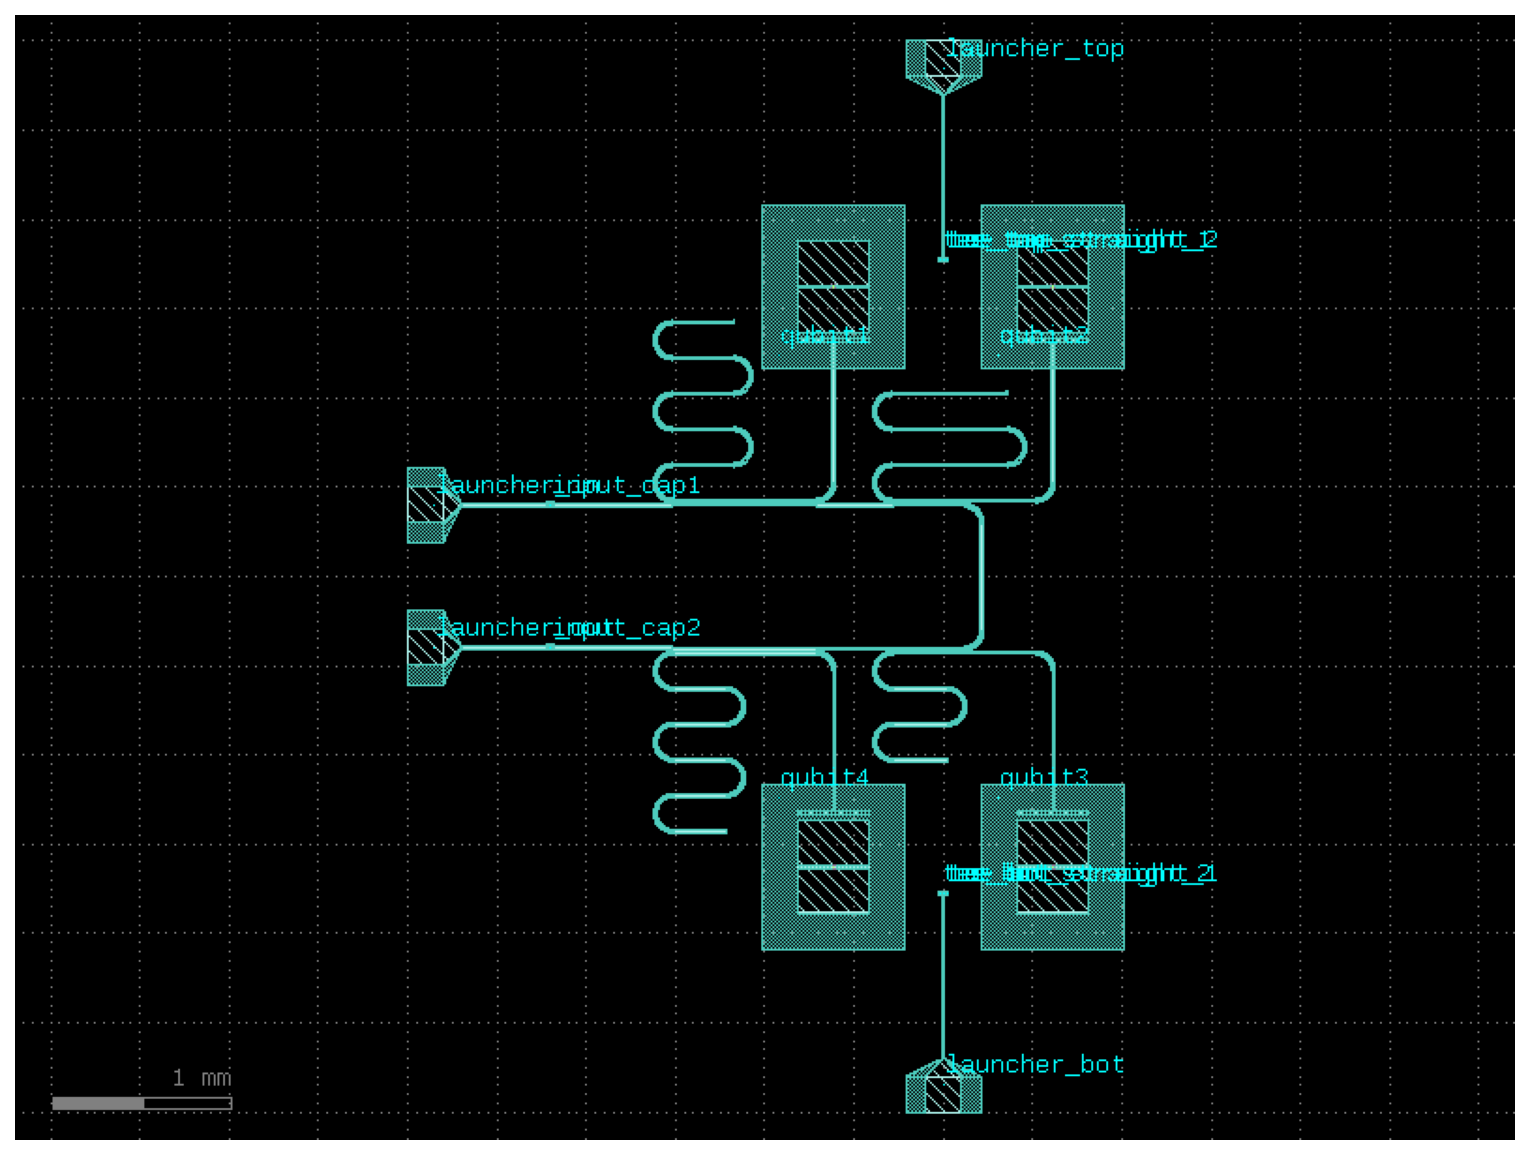

In [18]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "qubit_test_chip.png"   # QPDK's own render (MIT), from the local clone if present
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/qubit_test_chip.png")

## 15 · Summary

| | |
|---|---|
| **matches the source** | the four double-pad transmons (pads, pocket, coupler plate), the IDCs, the probeline's U-turn, the readout lengths and coupled sections at the source positions (λ/2, open), the flux-line ends, the launcher size |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; pads 100 µm from the die edge (longer leads); the whole layout centred (circuit +1660 µm in x, pads included; probeline leads 3638 µm, the circuit's east side 100 µm from the east die edge); sapphire; trilayer SQUIDs (f_q ≈ 5.8 GHz); the PDK cheese band |
| **simplified** | meanders before the coupled section (r = 50 µm); open flux-line ends without QPDK's tee; launcher ports 110 µm further in |
| **PDK design warnings** | none (SQUID R_n 45 kΩ in the window; pads at 100 µm) |
| **FEM** | 8 jobs (4 × Q3D, 4 × eigenmode/EPR) exported to `build/jobs/qubit_test_chip_*`, not solved here |